# TRUSTSR Lab 01.5 — Synthetic Recovery Strategy Comparison

**Status:** Synthetic simulation / research prototype. All results are generated from a fixed toy graph; no real agent traces or production systems are used.

## Objective
Compare:
1. **Full rollback (idealized checkpoint):** quarantine only the poison source and assume all other states are restored to valid checkpoint state.
2. **Observed reachability:** quarantine descendants reachable from the known poison source in the observed graph.
3. **Reachability + unknown quarantine:** also quarantine the endpoint and observed descendants of each explicitly declared missing edge.

The policies receive a missing-edge list supplied by the experiment controller. They do not discover missing edges. Ground truth is used only to score the results.

**Metrics:** false negatives, false-negative rate, over-quarantined unaffected states, preserved unaffected states, and unknown/unverified state count. These are synthetic simulation outputs—not evidence of real-world effectiveness.

## 1. Environment setup

In [1]:
%pip -q install networkx pandas matplotlib

In [2]:
import sys, platform
from datetime import datetime, timezone
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__, "| Pandas:", pd.__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1 | Pandas: 3.0.2
Execution UTC: 2026-10-11T10:26:26.265087+00:00
Evidence type: synthetic simulation only


## 2. Fixed synthetic ground truth

In [3]:
states = [
    {"id":"M1","label":"Trusted project requirement"},
    {"id":"M2","label":"Poisoned memory"},
    {"id":"D1","label":"Planning decision A"},
    {"id":"D2","label":"Planning decision B"},
    {"id":"P1","label":"Execution plan A"},
    {"id":"P2","label":"Execution plan B"},
    {"id":"A1","label":"Derived action record"},
    {"id":"S1","label":"Independent status note"},
]
dependencies = [("M1","D1"),("M2","D1"),("D1","P1"),("P1","A1"),
                ("M2","D2"),("D2","P2"),("M1","S1")]
SOURCE = "M2"
G_truth = nx.DiGraph()
for s in states:
    G_truth.add_node(s["id"], **s)
G_truth.add_edges_from(dependencies)
ALL = set(G_truth.nodes())
AFFECTED = set(nx.descendants(G_truth, SOURCE))
UNAFFECTED = ALL - AFFECTED - {SOURCE}
assert AFFECTED == {"D1","D2","P1","P2","A1"}
assert UNAFFECTED == {"M1","S1"}
print("Nodes:", len(ALL), "| Edges:", len(dependencies))
print("Expected affected descendants:", sorted(AFFECTED))
print("Unaffected states:", sorted(UNAFFECTED))
display(pd.DataFrame(dependencies, columns=["source","dependent"]))

Nodes: 8 | Edges: 7
Expected affected descendants: ['A1', 'D1', 'D2', 'P1', 'P2']
Unaffected states: ['M1', 'S1']


  source dependent
0     M1        D1
1     M2        D1
2     D1        P1
3     P1        A1
4     M2        D2
5     D2        P2
6     M1        S1

## 3. Policy definitions

In [4]:
def observed_graph(missing_edges):
    g = G_truth.copy()
    for edge in missing_edges:
        if not g.has_edge(*edge):
            raise ValueError(f"Invalid or duplicate missing edge: {edge}")
        g.remove_edge(*edge)
    return g

def reachability_quarantine(g):
    return set(nx.descendants(g, SOURCE))

def conservative_quarantine(g, missing_edges):
    q = reachability_quarantine(g)
    unknown = set()
    for _, v in missing_edges:
        if v in g:
            unknown.add(v)
            unknown.update(nx.descendants(g, v))
    unknown -= q
    unknown.discard(SOURCE)
    return q | unknown, unknown

def score(name, quarantined, unknown):
    fn = AFFECTED - quarantined
    over = UNAFFECTED & quarantined
    preserved = UNAFFECTED - quarantined
    return {
        "strategy": name,
        "quarantined_count": len(quarantined),
        "false_negative_count": len(fn),
        "false_negative_rate": len(fn)/len(AFFECTED),
        "over_quarantined_unaffected_count": len(over),
        "unaffected_states_preserved": len(preserved),
        "unaffected_preservation_rate": len(preserved)/len(UNAFFECTED),
        "unknown_unverified_count": len(unknown),
        "false_negative_states": sorted(fn),
        "over_quarantined_states": sorted(over),
        "quarantined_states": sorted(quarantined),
    }

print("Policies defined. Ground truth is not used to calculate policy outputs.")

Policies defined. Ground truth is not used to calculate policy outputs.


## 4. Run controlled edge-loss scenarios

In [5]:
SCENARIOS = [
    ("Complete graph", []),
    ("Missing D1 -> P1", [("D1","P1")]),
    ("Missing M2 -> D1", [("M2","D1")]),
    ("Missing both M2 outgoing edges", [("M2","D1"),("M2","D2")]),
    ("Missing D1 -> P1 and P1 -> A1", [("D1","P1"),("P1","A1")]),
    ("Missing unaffected branch M1 -> S1", [("M1","S1")]),
]
rows, state_rows = [], []
for scenario, missing in SCENARIOS:
    g = observed_graph(missing)
    base = reachability_quarantine(g)
    cons, unknown = conservative_quarantine(g, missing)
    # Idealized rollback restores every state except the poison source.
    rollback = {SOURCE}
    for name, q, u in [
        ("Full rollback (idealized checkpoint)", rollback, set()),
        ("Observed reachability", base, set()),
        ("Reachability + unknown quarantine", cons, unknown),
    ]:
        r = score(name, q, u)
        r["scenario"] = scenario
        r["missing_edges"] = "; ".join(f"{a}->{b}" for a,b in missing) or "(none)"
        rows.append(r)
        for node in sorted(ALL):
            if node == SOURCE:
                status = "confirmed_contaminated"
            elif node in base:
                status = "potentially_contaminated"
            elif node in u:
                status = "unknown_unverified"
            elif name.startswith("Full rollback") and node not in q:
                status = "restored_from_checkpoint"
            else:
                status = "not_quarantined"
            state_rows.append({
                "scenario":scenario, "strategy":name, "state_id":node,
                "synthetic_ground_truth_affected":node in AFFECTED,
                "quarantined":node in q, "unknown_unverified":node in u,
                "status":status
            })
results_df = pd.DataFrame(rows)
state_df = pd.DataFrame(state_rows)
display(results_df[["scenario","strategy","quarantined_count","false_negative_count",
                    "false_negative_rate","over_quarantined_unaffected_count",
                    "unaffected_states_preserved","unknown_unverified_count"]])

                              scenario                              strategy  quarantined_count  false_negative_count  false_negative_rate  over_quarantined_unaffected_count  \
0                       Complete graph  Full rollback (idealized checkpoint)                  1                     5                  1.0                                  0   
1                       Complete graph                 Observed reachability                  5                     0                  0.0                                  0   
2                       Complete graph     Reachability + unknown quarantine                  5                     0                  0.0                                  0   
3                     Missing D1 -> P1  Full rollback (idealized checkpoint)                  1                     5                  1.0                                  0   
4                     Missing D1 -> P1                 Observed reachability                  3                    

## 5. Plot false-negative rates

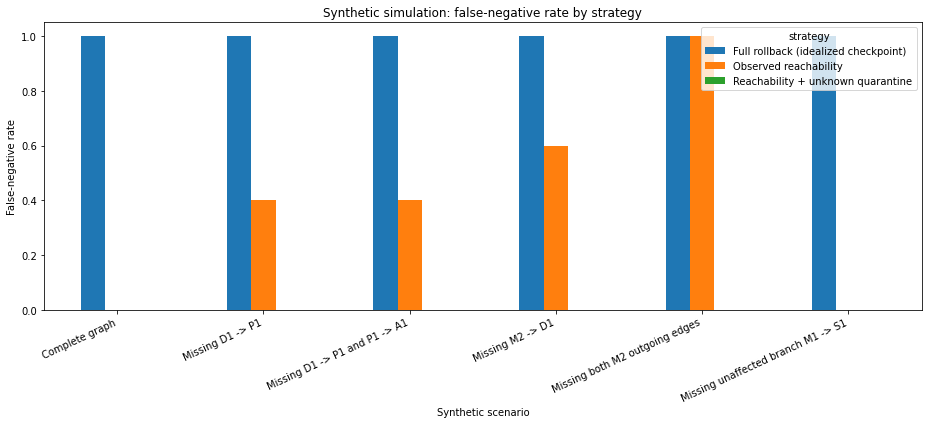

In [6]:
pivot = results_df.pivot(index="scenario", columns="strategy", values="false_negative_rate")
ax = pivot.plot(kind="bar", figsize=(13,6))
ax.set_ylabel("False-negative rate")
ax.set_xlabel("Synthetic scenario")
ax.set_title("Synthetic simulation: false-negative rate by strategy")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 6. Plot preservation and quarantine trade-off

                               strategy  mean_false_negative_rate  mean_unaffected_preservation_rate  mean_over_quarantined  mean_unknown_states
0  Full rollback (idealized checkpoint)                       1.0                           1.000000               0.000000             0.000000
1                 Observed reachability                       0.4                           1.000000               0.000000             0.000000
2     Reachability + unknown quarantine                       0.0                           0.916667               0.166667             2.166667

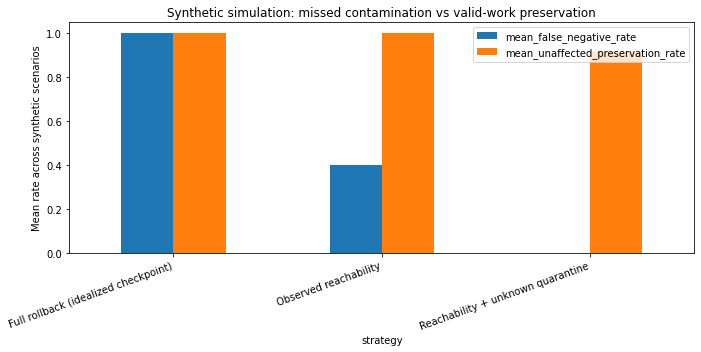

In [7]:
summary = results_df.groupby("strategy", as_index=False).agg(
    mean_false_negative_rate=("false_negative_rate","mean"),
    mean_unaffected_preservation_rate=("unaffected_preservation_rate","mean"),
    mean_over_quarantined=("over_quarantined_unaffected_count","mean"),
    mean_unknown_states=("unknown_unverified_count","mean"),
)
display(summary)
ax = summary.set_index("strategy")[["mean_false_negative_rate","mean_unaffected_preservation_rate"]].plot(kind="bar", figsize=(10,5))
ax.set_ylabel("Mean rate across synthetic scenarios")
ax.set_title("Synthetic simulation: missed contamination vs valid-work preservation")
ax.set_ylim(0,1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 7. Inspect the multiple-edge failure scenario

In [8]:
display(state_df[state_df["scenario"]=="Missing both M2 outgoing edges"][
    ["strategy","state_id","synthetic_ground_truth_affected","quarantined","unknown_unverified","status"]
].sort_values(["strategy","state_id"]))
print("Interpretation: policy behavior depends on the explicitly supplied missing-edge list.")
print("This is not automatic missing-edge detection and not proof of real-world recovery.")

                                strategy state_id  synthetic_ground_truth_affected  quarantined  unknown_unverified                    status
72  Full rollback (idealized checkpoint)       A1                             True        False               False  restored_from_checkpoint
73  Full rollback (idealized checkpoint)       D1                             True        False               False  restored_from_checkpoint
74  Full rollback (idealized checkpoint)       D2                             True        False               False  restored_from_checkpoint
75  Full rollback (idealized checkpoint)       M1                            False        False               False  restored_from_checkpoint
76  Full rollback (idealized checkpoint)       M2                            False         True               False    confirmed_contaminated
77  Full rollback (idealized checkpoint)       P1                             True        False               False  restored_from_checkpoint
78  Fu

Interpretation: policy behavior depends on the explicitly supplied missing-edge list.
This is not automatic missing-edge detection and not proof of real-world recovery.


## 8. Assertions and consistency checks

In [9]:
def row_for(scenario, strategy):
    return results_df[(results_df.scenario==scenario) & (results_df.strategy==strategy)].iloc[0]

assert row_for("Complete graph","Observed reachability").false_negative_count == 0
assert row_for("Missing D1 -> P1","Reachability + unknown quarantine").false_negative_count == 0
assert row_for("Missing D1 -> P1","Reachability + unknown quarantine").unknown_unverified_count == 2
assert row_for("Missing both M2 outgoing edges","Observed reachability").false_negative_count == 5
assert row_for("Missing both M2 outgoing edges","Reachability + unknown quarantine").false_negative_count == 0
assert row_for("Missing unaffected branch M1 -> S1","Observed reachability").false_negative_count == 0
for c in ["false_negative_rate","unaffected_preservation_rate"]:
    assert results_df[c].between(0,1).all()
assert not results_df.duplicated(["scenario","strategy"]).any()
assert len(results_df) == len(SCENARIOS)*3

print("PASS: complete graph reachability detects all expected affected descendants.")
print("PASS: missing internal edge produces two unknown states.")
print("PASS: both missing source edges remain covered only because their missing-edge signals are supplied.")
print("PASS: unaffected-branch removal creates no false negatives.")
print("PASS: metrics are bounded and each scenario-strategy pair is unique.")
print("All Lab 01.5 assertions passed.")

PASS: complete graph reachability detects all expected affected descendants.
PASS: missing internal edge produces two unknown states.
PASS: both missing source edges remain covered only because their missing-edge signals are supplied.
PASS: unaffected-branch removal creates no false negatives.
PASS: metrics are bounded and each scenario-strategy pair is unique.
All Lab 01.5 assertions passed.


## 9. Export CSV artifacts

In [10]:
results_df.to_csv("trustsr_lab01_5_recovery_strategy_comparison.csv", index=False)
state_df.to_csv("trustsr_lab01_5_state_dispositions.csv", index=False)
summary.to_csv("trustsr_lab01_5_strategy_summary.csv", index=False)
print("Generated files:")
print("- trustsr_lab01_5_recovery_strategy_comparison.csv")
print("- trustsr_lab01_5_state_dispositions.csv")
print("- trustsr_lab01_5_strategy_summary.csv")

Generated files:
- trustsr_lab01_5_recovery_strategy_comparison.csv
- trustsr_lab01_5_state_dispositions.csv
- trustsr_lab01_5_strategy_summary.csv


## 10. Interpretation and limitations

- **Full rollback is idealized:** it assumes a trusted checkpoint can restore every non-poison state. Real systems may lose valid post-checkpoint work or have irreversible external effects.
- **Missing edges are supplied:** this notebook does not discover missing dependencies.
- **Tiny fixed graph:** results cannot be generalized to real systems or used to support numerical claims in the TRUSTSR monograph.
- **No recovery engine:** this is a policy comparison, not an implementation of checkpoint restoration, side-effect compensation, or trusted-state verification.

All values are synthetic simulation outputs for this graph and these scenarios. A stronger follow-up would use generated graphs, randomized missing-edge patterns, repeated trials, declared cost functions, and independent review.